# 00 · Overview and setup

This series reproduces **Moulinas & Waintal, *A multilevel tensor network compression technique for simulating Lindblad dynamics in superconducting circuits*, arXiv:2605.27515**, with the `qttlind` Python library described in the implementation guide.

| Notebook | Paper content |
|---|---|
| 01 Quantics tensor trains | Sec. II A, Fig. 2 |
| 02 Bosonic MPOs | Sec. II B, Fig. 3, Table I |
| 03 Fock vs position | Sec. II C, Figs. 4–5 |
| 04 Closed-system integrators | Sec. III, Fig. 6 |
| 05 Purified Lindblad with Kraus maps | Secs. IV–V, Figs. 7–9 |
| 06 Cat qubit Z gate | Sec. VI, Figs. 1 and 10 |
| 07 Transmon branch analysis | App. A, Fig. 13 |
| 08 Transmon ionization | Sec. VII, Figs. 11–12 |

The **CV extension** adds benchmark notebooks for continuous-variable optics, each
reproducing an analytic or published result and ending with an acceptance table:

| Notebook | Benchmark |
|---|---|
| 09 Gaussian benchmarks | squeezing statistics and loss, TMSV entanglement, Gaussian boson sampling (Hamilton et al. 2017) |
| 10 Photon subtraction | Schrödinger kittens (Dakna et al. 1997; Ourjoumtsev et al. 2006) |
| 11 GKP in position space | ranks Fock vs position, Wigner, homodyne readout under noise (GKP 2001) |
| 12 Kerr, cubic phase, Fourier | Yurke–Stoler cats (1986), quantics Fourier ranks (Chen et al. 2023) |
| 13 Cluster states, digital twin | time-multiplexed 1D clusters (Menicucci 2011), a hardware noise budget |

**Two backends.** Every notebook checks which capabilities the installed `qttlind` implements (`qttlind.FEATURES`).
* Until `qttlind` implements everything the tutorials call (`qtt`, `mpo`, `closed`, `comb`, `lindblad`, `api`), cells run on the dense NumPy oracle `qttlind.reference.dense_ref` at reduced sizes. The physics and the checks are the same; only the Hilbert-space sizes are smaller.
* Once it does (`PAPER_SIZE = True`), the same cells run the published sizes through the QTT solver.

The oracle implements exactly the purified second-order Kraus scheme of Sec. V, so it is also the reference the QTT solver is tested against.

## Installing qttlind

```bash
curl -LsSf https://astral.sh/uv/install.sh | sh     # once
uv sync                                             # in the repository root
uv run jupyter lab notebooks/
```
The notebooks also run from a plain checkout without installing (they fall back to `../src`). The banner below reports the run mode: **quick** by default (reduced sizes, QTT runs cross-checked against the dense oracle, minutes), **published sizes** with `QTTLIND_PAPER_SIZE=1` (hours).

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


## Smoke test: a damped harmonic oscillator

$H=\omega a^\dagger a$, $L=\sqrt{\kappa}\,a$, starting from a coherent state. The exact result is $\langle n\rangle(t)=|\alpha_0|^2 e^{-\kappa t}$ and the state stays pure (a coherent state), so $\chi_\mu$ should stay at 1.

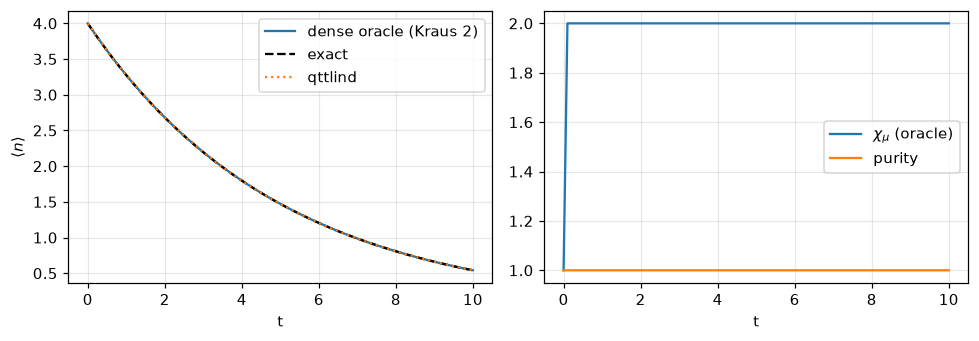

max |<n> - exact| = 0.000741555281286832


In [2]:
N, omega, kappa, alpha0 = 32, 1.0, 0.2, 2.0
a = dr.destroy(N)
H = omega * a.conj().T @ a
Ls = [np.sqrt(kappa) * a]
res = dr.evolve(dr.coherent(N, alpha0), H, Ls, t_final=10.0, h=0.01,
                e_ops={"n": a.conj().T @ a}, every=10)

if HAVE_QTTLIND:
    sysq = ql.System(); am = sysq.add_mode("cav", bits=5)
    sol = ql.LindbladSolver(sysq, omega * am.n(), [np.sqrt(kappa) * am], scheme="kraus2", dt=0.01, tol=1e-8)
    resq = sol.run(sysq.product_state(cav=ql.states.coherent(alpha0)), t_final=10.0,
                   e_ops={"n": am.n()}, every=10, track=["chi_mu"])

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(res.times, res.expect["n"].real, label="dense oracle (Kraus 2)")
ax[0].plot(res.times, alpha0**2 * np.exp(-kappa * res.times), "k--", label="exact")
if HAVE_QTTLIND:
    ax[0].plot(resq.times, np.real(resq.expect["n"]), ":", label="qttlind")
ax[0].set(xlabel="t", ylabel=r"$\langle n\rangle$"); ax[0].legend()
ax[1].plot(res.times, res.chi_mu, label=r"$\chi_\mu$ (oracle)")
ax[1].plot(res.times, res.purity, label="purity")
ax[1].set(xlabel="t"); ax[1].legend()
plt.tight_layout(); plt.show()
print("max |<n> - exact| =", np.abs(res.expect["n"].real - alpha0**2*np.exp(-kappa*res.times)).max())